# Galaxy and Halo Data Utilities

High-level filtered readers that return NumPy arrays or Polars DataFrames. Prefer these over the low-level `read_snapshot_data` for analysis work.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import oh_mpl_paper

import galform_analysis
from galform_analysis import set_base_dir, get_base_dir, SimulationConfig, load_redshift_mapping

oh_mpl_paper.setconfig("k.wang")

# Configure the path to your GALFORM output directory once per session:
# set_base_dir('/cosma5/data/durham/<user>/Galform_Out/L800/model')
BASE_DIR = str(get_base_dir())
SIM = 'L800'

## Galaxy arrays (central galaxies only)

In [2]:
from galform_analysis.utils.read_galaxies import read_galaxy_arrays, read_galaxy_positions
import os

iz_path = os.path.join(BASE_DIR, 'iz155')

arrays, meta = read_galaxy_arrays(iz_path, ivol=0, centrals_only=True)
print(f"Fields  : {list(arrays.keys())}")
print(f"N_gal   : {len(arrays['x']):,}  (centrals only)")
print(f"z       : {meta['z']:.4f}")
print(f"V_ivol  : {meta['V_ivol']:.1f} (Mpc/h)^3")

Fields  : ['x', 'y', 'z', 'mstar', 'mhalo', 'sfr', 'is_central']
N_gal   : 146,786  (centrals only)
z       : 1.4955
V_ivol  : 155626.1 (Mpc/h)^3


## All galaxies with a stellar-mass cut

In [3]:
arrays_all, meta = read_galaxy_arrays(
    iz_path, ivol=0,
    centrals_only=False,
    mstar_min=1e9,          # M_sun/h
)
print(f"All galaxies with M* > 1e9 M_sun/h: {len(arrays_all['x']):,}")

All galaxies with M* > 1e9 M_sun/h: 3,605


## Positions only (NumPy array)

In [4]:
from galform_analysis.utils.read_galaxies import read_galaxy_positions, read_halo_positions

pos_gal, z = read_galaxy_positions(iz_path, ivol=0, centrals_only=True)
pos_halo, _ = read_halo_positions(iz_path, ivol=0)

print(f"Galaxy positions shape : {pos_gal.shape}   z={z:.4f}")
print(f"Halo   positions shape : {pos_halo.shape}")

Galaxy positions shape : (146786, 3)   z=1.4955
Halo   positions shape : (146786, 3)


## Galaxy positions in 2-D projection

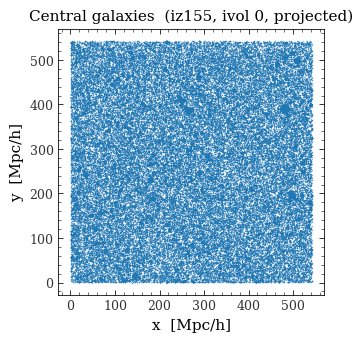

In [5]:
fig, ax = plt.subplots(figsize=(3.31, 3.31))
ax.scatter(pos_gal[:, 0], pos_gal[:, 1], s=0.3, alpha=0.4, rasterized=True)
ax.set_xlabel('x  [Mpc/h]')
ax.set_ylabel('y  [Mpc/h]')
ax.set_title('Central galaxies  (iz155, ivol 0, projected)')
ax.set_aspect('equal')
plt.show()

## Polars DataFrame interface

In [6]:
from galform_analysis.utils.read_galaxies import read_galaxies_dataframe

df, meta = read_galaxies_dataframe(iz_path, ivol=0, return_metadata=True)
print(df.head())
print(f"\n{len(df):,} central galaxies,  z={meta['z']:.4f}")

shape: (5, 7)
┌────────────┬────────────┬────────────┬──────────────┬───────────┬─────────────┬────────────┐
│ x          ┆ y          ┆ z          ┆ mstar        ┆ mhalo     ┆ sfr         ┆ is_central │
│ ---        ┆ ---        ┆ ---        ┆ ---          ┆ ---       ┆ ---         ┆ ---        │
│ f32        ┆ f32        ┆ f32        ┆ f32          ┆ f32       ┆ f32         ┆ i32        │
╞════════════╪════════════╪════════════╪══════════════╪═══════════╪═════════════╪════════════╡
│ 288.41983  ┆ 59.595661  ┆ 490.922394 ┆ 9.069639e6   ┆ 7.2124e9  ┆ 6176508.5   ┆ 1          │
│ 307.757141 ┆ 14.295116  ┆ 503.374756 ┆ 920184.9375  ┆ 2.2274e9  ┆ 616169.9375 ┆ 1          │
│ 295.218018 ┆ 66.393608  ┆ 476.620453 ┆ 3615150.5    ┆ 1.0501e10 ┆ 4324953.5   ┆ 1          │
│ 108.650749 ┆ 166.710648 ┆ 516.107361 ┆ 1.4403e6     ┆ 4.4547e9  ┆ 1.386396e6  ┆ 1          │
│ 328.797516 ┆ 7.853461   ┆ 507.867798 ┆ 337022.96875 ┆ 2.1213e9  ┆ 282860.375  ┆ 1          │
└────────────┴────────────┴─────────